## 
#### Name : AKASH CT
#### Reg No: 212224240007

In [2]:
# Import libraries
import cv2
import numpy as np
import matplotlib.pyplot as plt

Text(0.5, 1.0, 'Face')

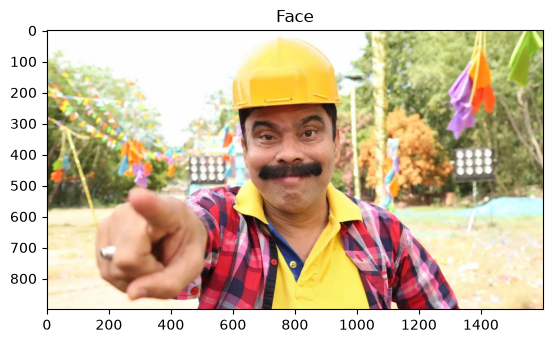

In [3]:
# Load the Face Image
faceImage = cv2.imread('power.jpeg')
plt.imshow(faceImage[:,:,::-1]);plt.title("Face")


In [4]:
faceImage.shape

(900, 1600, 3)

In [5]:
#resized_faceImage.shape
faceImage.shape

(900, 1600, 3)

Text(0.5, 1.0, 'glassPNG')

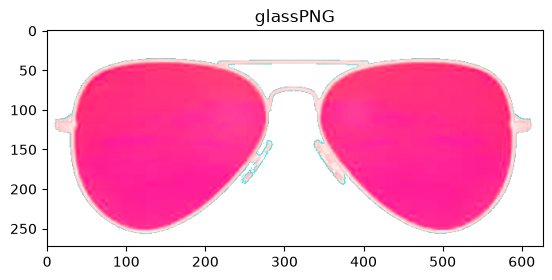

In [6]:
# Load the Sunglass image with Alpha channel
glassPNG = cv2.imread('kannadi.png',-1)
plt.imshow(glassPNG[:,:,::-1]);plt.title("glassPNG")

In [50]:
glassPNG = cv2.resize(glassPNG, (1520, 400))
print("Image Dimension = {}".format(glassPNG.shape))

Image Dimension = (400, 1520, 4)


In [51]:
# Separate the Color and alpha channels
glassBGR = glassPNG[:,:,0:3]
glassMask1 = glassPNG[:,:,3]

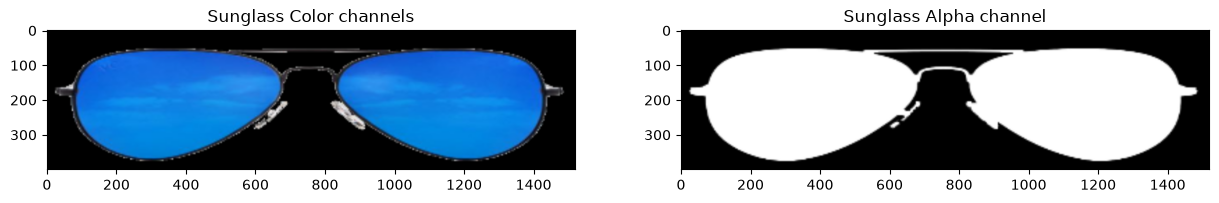

In [52]:
# Display the images for clarity
plt.figure(figsize=[15,15])
plt.subplot(121);plt.imshow(glassBGR[:,:,::-1]);plt.title('Sunglass Color channels');
plt.subplot(122);plt.imshow(glassMask1,cmap='gray');plt.title('Sunglass Alpha channel');

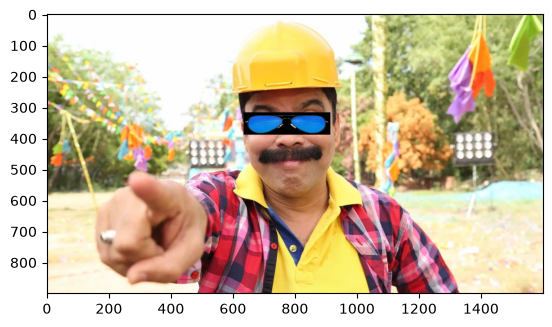

In [57]:
faceWithGlassesNaive = faceImage.copy()

# Slightly larger sunglasses
glassResized = cv2.resize(glassBGR, (280, 72))

# Matching region: height = 72, width = 280
faceWithGlassesNaive[316:388, 635:915] = glassResized

plt.imshow(faceWithGlassesNaive[..., ::-1])
plt.show()

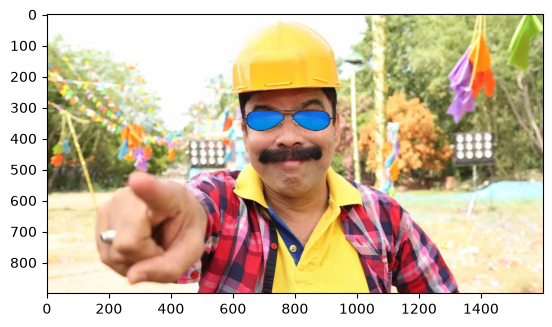

In [65]:
# Resize sunglasses and mask to 300x80
glassBGR = cv2.resize(glassBGR, (300, 80))
glassMask1 = cv2.resize(glassMask1, (300, 80))

# Create 3-channel binary mask
glassMask = cv2.merge((glassMask1, glassMask1, glassMask1))
glassMask = np.uint8(glassMask > 0)

faceWithGlassesArithmetic = faceImage.copy()

# Extract matching eye region
eyeROI = faceWithGlassesArithmetic[300:380, 630:930]

# Apply masks
maskedEye = cv2.multiply(eyeROI, 1 - glassMask)
maskedGlass = cv2.multiply(glassBGR, glassMask)

# Combine both regions
eyeRoiFinal = cv2.add(maskedEye, maskedGlass)

# Insert the result
faceWithGlassesArithmetic[300:380, 630:930] = eyeRoiFinal

plt.imshow(faceWithGlassesArithmetic[..., ::-1])
plt.show()

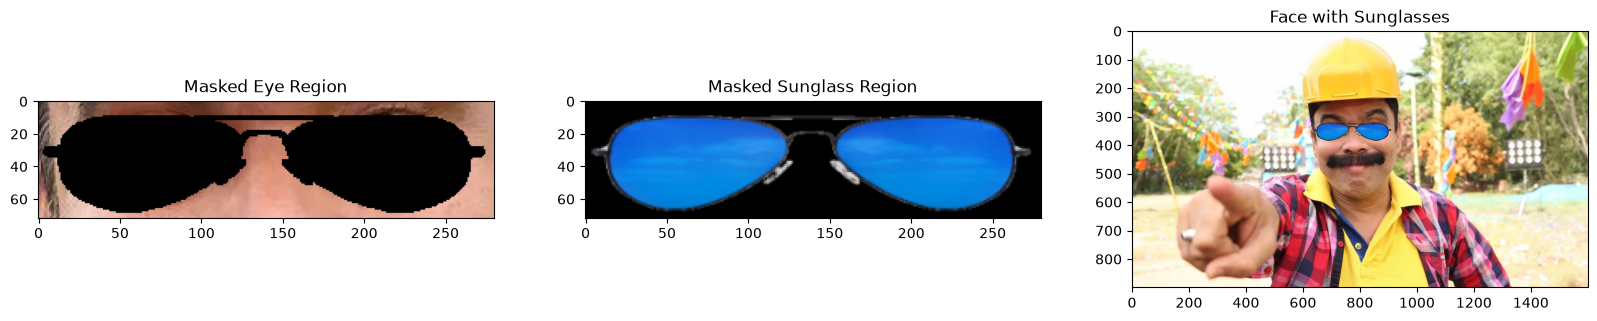

In [68]:
# Resize sunglasses and mask to the same dimensions
glassBGR = cv2.resize(glassBGR, (280, 72))
glassMask1 = cv2.resize(glassMask1, (280, 72))

# Create a 3-channel mask with values 0 and 1
glassMask = np.uint8(glassMask1 > 0)
glassMask = cv2.merge((glassMask, glassMask, glassMask))

# Make a copy
faceWithGlassesArithmetic = faceImage.copy()

# Get the eye region (height = 72, width = 280)
eyeROI = faceWithGlassesArithmetic[316:388, 635:915]

# Mask the eye region
maskedEye = cv2.multiply(eyeROI, 1 - glassMask)

# Mask the sunglasses
maskedGlass = cv2.multiply(glassBGR, glassMask)

# Combine both regions
eyeRoiFinal = cv2.add(maskedEye, maskedGlass)

# Insert the result into the face image
faceWithGlassesArithmetic[316:388, 635:915] = eyeRoiFinal

# Display results
plt.figure(figsize=(20, 6))
plt.subplot(131)
plt.imshow(maskedEye[..., ::-1])
plt.title("Masked Eye Region")

plt.subplot(132)
plt.imshow(maskedGlass[..., ::-1])
plt.title("Masked Sunglass Region")

plt.subplot(133)
plt.imshow(faceWithGlassesArithmetic[..., ::-1])
plt.title("Face with Sunglasses")

plt.show()

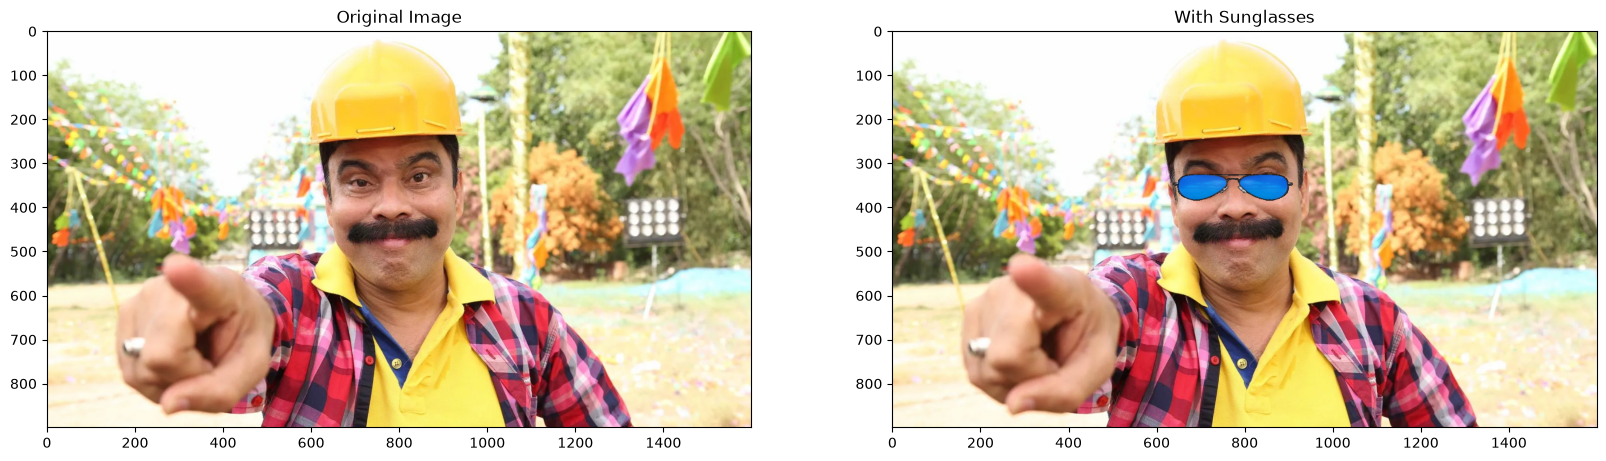

In [72]:
# Replace the eye ROI with the output from the previous section
faceWithGlassesArithmetic[316:388, 635:915] = eyeRoiFinal

# Display the final result
plt.figure(figsize=[20, 20])

plt.subplot(121)
plt.imshow(faceImage[:, :, ::-1])
plt.title("Original Image")

plt.subplot(122)
plt.imshow(faceWithGlassesArithmetic[:, :, ::-1])
plt.title("With Sunglasses")

plt.show()